In [1]:
from sklearn.datasets import load_digits
import pandas as pd

digits = load_digits()

X = digits.data
y = digits.target

df = pd.DataFrame(X)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,54,55,56,57,58,59,60,61,62,63
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0


#Exercise 1

Scale the dataset using StandardScaler.

In [2]:
from sklearn.preprocessing import StandardScaler

In [3]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

#Exercise 2

Apply PCA to reduce the dataset to:

```
2 components
```

Store result in:
```
X_pca
```

In [4]:
from sklearn.decomposition import PCA

In [5]:
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_scaled)
print(X_pca.shape)

(1797, 2)


#Exercise 3

Create a scatter plot of:
```
PC1 vs PC2
```

Color points using digit labels.

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

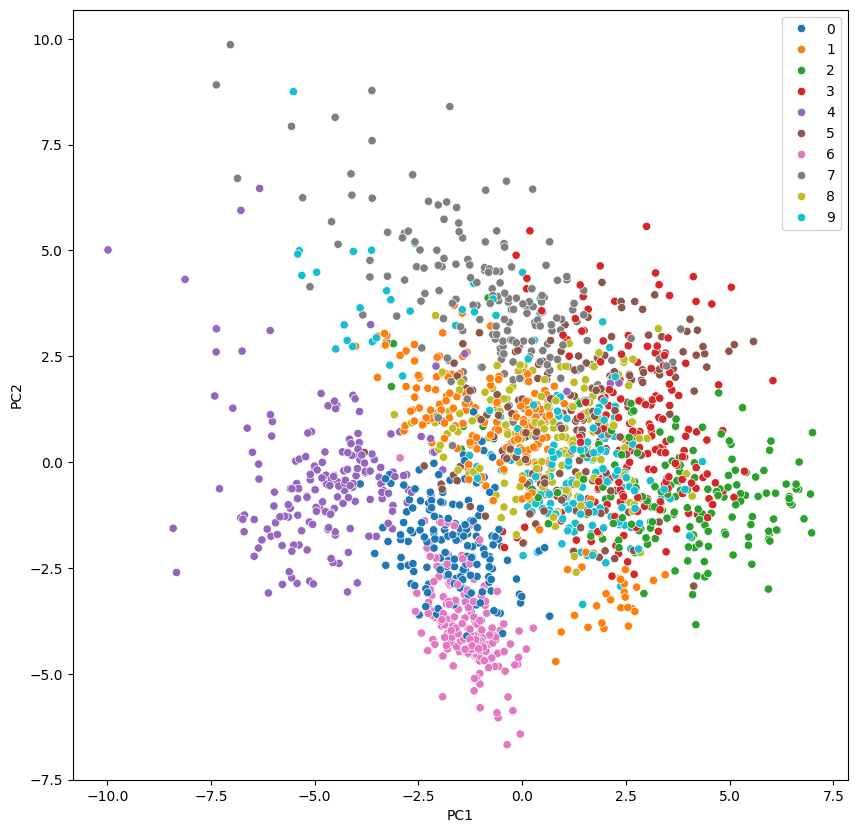

In [7]:
plt.figure(figsize=(10,10))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=y, palette='tab10')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

#Exercise 4

Train KMeans clustering on the PCA data.

Use:
```
n_clusters = 10
```

In [8]:
from sklearn.cluster import KMeans

In [9]:
kmeans=KMeans(n_clusters=10, random_state=42)
clusters=kmeans.fit_predict(X_pca)

#Exercise 5

Visualize the clusters produced by KMeans.

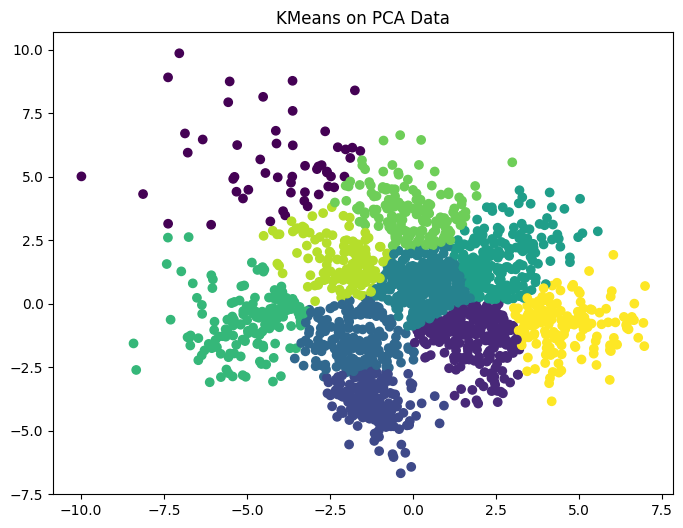

In [10]:
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters, cmap="viridis")
plt.title("KMeans on PCA Data")
plt.show()

#Exercise 6

Apply t-SNE to reduce the dataset to 2 dimensions.

In [11]:
from sklearn.manifold import TSNE

In [12]:
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)
print(X_tsne.shape)

(1797, 2)


#Exercise 7

Plot the t-SNE output.

Compare it with the PCA plot.

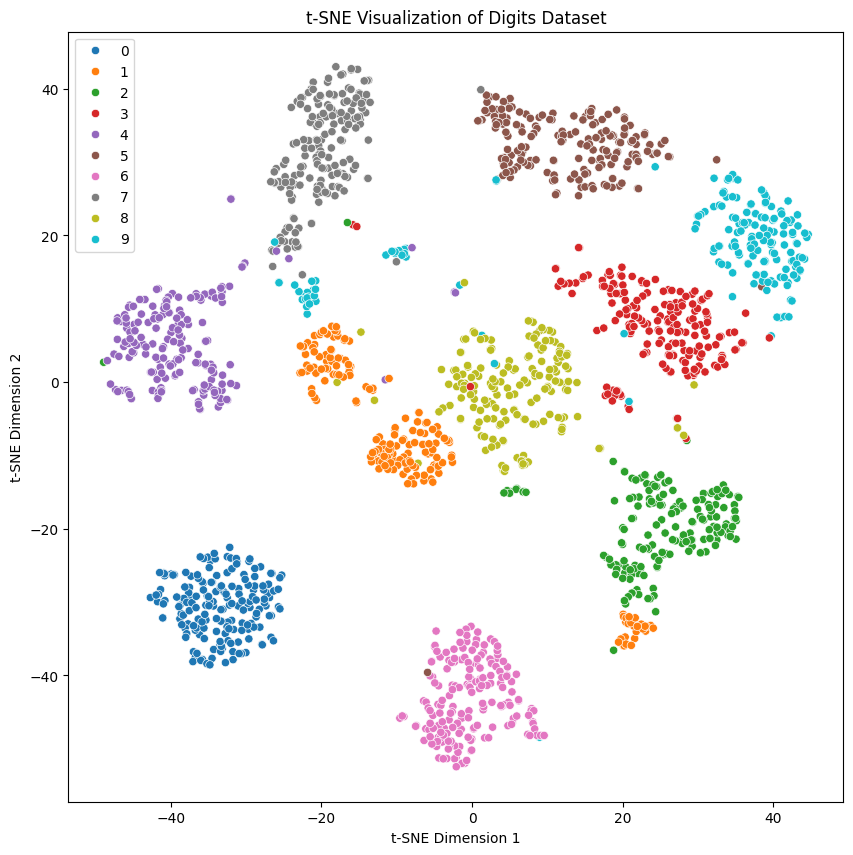

In [13]:
plt.figure(figsize=(10, 10))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y, palette='tab10')
plt.title('t-SNE Visualization of Digits Dataset')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.show()

In [14]:
# t-SNE visualization shows more distinct groups of digits compared to PCA, where some digit classes overlap.
# this is because t-SNE focuses on preserving local relationships, while PCA preserves directions of maximum variance.

#Exercise 8 (Conceptual)

###Question:

Why is dimensionality reduction useful before clustering?




In [15]:
# dimensionality reduction helps simplify the dataset by reducing the number of features while preserving important information.
# this can make clustering faster, reduce noise, and help us visualize the clusters more easily.